<center><h1>Zhang_Zhengshu_HW7</h1></center>

Name: Zhengshu Zhang
<br>
Github Username: forestzs
<br>
USC ID: 4664738582

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import recall_score, silhouette_score
from sklearn.cluster import KMeans
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### (a) Download the Anuran Calls (MFCCs) Data Set

The Anuran Calls (MFCCs) data set comes from the UCI Machine Learning Repository [1]. Its two files, Frogs_MFCCs.csv and Readme.txt, are stored in the folder data/AnuranCalls. Each row is one syllable cut from a recording of a frog call. The first 22 columns are the Mel-frequency cepstral coefficients (MFCCs) of the syllable, which describe its sound. The next three columns are the labels Family, Genus and Species. The last column, RecordID, numbers the recording that the syllable comes from. It is neither a feature nor a label, so it is dropped. The Readme says that the MFCCs are already scaled, in its words "These coefficients were normalized between -1 <= mfcc <= 1".

In [2]:
data = pd.read_csv("data/AnuranCalls/Frogs_MFCCs.csv")
mfcc_cols = ["MFCCs_%2d" % i for i in range(1, 23)]
label_cols = ["Family", "Genus", "Species"]

assert data.shape == (7195, 26)
assert list(data.columns) == mfcc_cols + label_cols + ["RecordID"]
assert data.isna().sum().sum() == 0

X_all = data[mfcc_cols].to_numpy()
Y_all = data[label_cols]

print("rows and columns:", data.shape, "  missing values:", int(data.isna().sum().sum()))
print("MFCC columns: '%s' to '%s', %d columns" % (mfcc_cols[0], mfcc_cols[-1], len(mfcc_cols)))
print("smallest MFCC value: %.4f   largest MFCC value: %.4f" % (X_all.min(), X_all.max()))
print("standard deviation of the MFCCs: smallest %.4f, largest %.4f"
      % (data[mfcc_cols].std().min(), data[mfcc_cols].std().max()))
print("distinct RecordID values:", data["RecordID"].nunique())
for col in label_cols:
    counts = data[col].value_counts()
    print()
    print("%s, %d classes" % (col, len(counts)))
    print(counts.to_string())
print()
print("number of rows of each (family, genus, species) combination")
print(data.groupby(label_cols).size().to_string())

rows and columns: (7195, 26)   missing values: 0
MFCC columns: 'MFCCs_ 1' to 'MFCCs_22', 22 columns
smallest MFCC value: -0.9523   largest MFCC value: 1.0000
standard deviation of the MFCCs: smallest 0.0690, largest 0.2635
distinct RecordID values: 60

Family, 4 classes
Family
Leptodactylidae    4420
Hylidae            2165
Dendrobatidae       542
Bufonidae            68

Genus, 8 classes
Genus
Adenomera        4150
Hypsiboas        1593
Ameerega          542
Dendropsophus     310
Leptodactylus     270
Scinax            148
Osteocephalus     114
Rhinella           68

Species, 10 classes
Species
AdenomeraHylaedactylus    3478
HypsiboasCordobae         1121
AdenomeraAndre             672
Ameeregatrivittata         542
HypsiboasCinerascens       472
HylaMinuta                 310
LeptodactylusFuscus        270
ScinaxRuber                148
OsteocephalusOophagus      114
Rhinellagranulosa           68

number of rows of each (family, genus, species) combination
Family           Genus    

The data have 7195 rows and 26 columns and no missing value. Every MFCC lies between -0.9523 and 1.0000, which agrees with the Readme. RecordID has 60 distinct values, so the rows come from 60 recordings. Family has 4 classes, from Leptodactylidae with 4420 rows down to Bufonidae with 68 rows. Genus has 8 classes, from Adenomera with 4150 rows down to Rhinella with 68 rows. Species has 10 classes, from AdenomeraHylaedactylus with 3478 rows down to Rhinellagranulosa with 68 rows. So all three labels are imbalanced. The last table shows that each species belongs to exactly one genus and each genus to exactly one family. The 68 rows of Rhinellagranulosa are all the rows of Rhinella and all the rows of Bufonidae, so the smallest class is the same set of rows at every level.

The handout asks for 70% of the rows, chosen at random, as the training set. The split uses train_test_split with test_size=0.3 and random_state=0, and the other 30% of the rows form the test set. The split is stratified by Species. The smallest species has only 68 rows, so a plain random split could leave very few of them in one of the two sets. Each species belongs to exactly one genus and one family, as the last table above shows. So stratifying by Species also keeps the class shares of Genus and Family.

In [3]:
X_train, X_test, Y_train, Y_test = train_test_split(X_all, Y_all, test_size=0.3, random_state=0,
                                                    stratify=Y_all["Species"])
print("training rows:", len(X_train), "  test rows:", len(X_test))
shares = []
for col in label_cols:
    table = pd.DataFrame({"training set": Y_train[col].value_counts(), "test set": Y_test[col].value_counts()})
    table = table.sort_values("training set", ascending=False)
    table["share in training set"] = table["training set"] / (table["training set"] + table["test set"])
    shares += list(table["share in training set"])
    print()
    print(table.to_string(formatters={"share in training set": "{:.4f}".format}))
print()
print("share of each class in the training set: lowest %.4f, highest %.4f" % (min(shares), max(shares)))

training rows: 5036   test rows: 2159

                 training set  test set share in training set
Family                                                       
Leptodactylidae          3093      1327                0.6998
Hylidae                  1516       649                0.7002
Dendrobatidae             379       163                0.6993
Bufonidae                  48        20                0.7059

               training set  test set share in training set
Genus                                                      
Adenomera              2904      1246                0.6998
Hypsiboas              1115       478                0.6999
Ameerega                379       163                0.6993
Dendropsophus           217        93                0.7000
Leptodactylus           189        81                0.7000
Scinax                  104        44                0.7027
Osteocephalus            80        34                0.7018
Rhinella                 48        20           

The training set has 5036 rows and the test set has 2159 rows. For every class of every label, the share of its rows in the training set lies between 0.6992 and 0.7059, so every class is split close to 70/30. The smallest class, Rhinellagranulosa, has 48 training rows and 20 test rows, and so do Bufonidae and Rhinella.

### (b) Train a classifier for each label

Binary relevance trains a separate multi-class classifier for each of the three labels, Family, Genus and Species. The three predictions for a row then form its predicted triplet (family, genus, species).

#### (i) Research

The measures below follow the review of multi-label learning by Zhang and Zhou [2]. For row $i$ of $n$ rows, $Y_i$ is the set of its three true labels (family, genus, species) and $Z_i$ is the set of its three predicted labels. The Hamming distance $d_i$ of row $i$ is the number of its three labels that are predicted wrongly, so $d_i$ is 0, 1, 2 or 3.

- The exact match ratio is the share of rows whose three labels are all right, $\frac{1}{n}\sum_{i=1}^{n} I(Z_i = Y_i)$, where $I(\cdot)$ is 1 when the condition holds and 0 otherwise.
- The Hamming loss is the share of wrongly predicted row-label pairs, $\frac{1}{n}\sum_{i=1}^{n} \frac{d_i}{3}$.
- The Hamming score is the measure that the review calls example-based accuracy, $\frac{1}{n}\sum_{i=1}^{n} \frac{|Y_i \cap Z_i|}{|Y_i \cup Z_i|}$. The review lists Godbole and Sarawagi among the sources of these measures. No class name is shared between the three labels, as the code below checks. So $Y_i \cap Z_i$ holds $3 - d_i$ labels, $Y_i \cup Z_i$ holds $3 + d_i$ labels, and the Hamming score equals $\frac{1}{n}\sum_{i=1}^{n} \frac{3 - d_i}{3 + d_i}$.
- The mean Hamming distance is $\bar{d} = \frac{1}{n}\sum_{i=1}^{n} d_i$.

Both kinds of measures are used because they answer different questions. The exact match ratio only counts fully right triplets, while the Hamming measures also give credit for partly right ones. The function below computes all four measures, and it is used for every classifier of 1(b) and for Problem 2. It is checked on three made-up rows.

In [4]:
def multilabel_scores(Y_true, Y_pred):
    """Exact match ratio, Hamming loss, Hamming score and mean Hamming distance of label triplets.
    Y_true and Y_pred have one row per instance and one column per label (family, genus, species)."""
    Y_true = np.asarray(Y_true)
    Y_pred = np.asarray(Y_pred)
    n_labels = Y_true.shape[1]
    d = (Y_true != Y_pred).sum(axis=1)          # Hamming distance d_i of each row
    return {"exact match ratio": np.mean(d == 0),
            "Hamming loss": np.mean(d / n_labels),
            "Hamming score": np.mean((n_labels - d) / (n_labels + d)),
            "mean Hamming distance": np.mean(d)}


family, genus, species = set(data["Family"]), set(data["Genus"]), set(data["Species"])
print("class names that appear in more than one label:", len((family & genus) | (family & species) | (genus & species)))
print()
truth = [["Hylidae", "Scinax", "ScinaxRuber"]] * 3
guess = [["Hylidae", "Scinax", "ScinaxRuber"],
         ["Hylidae", "Scinax", "HylaMinuta"],
         ["Bufonidae", "Rhinella", "Rhinellagranulosa"]]
for t, g in zip(truth, guess):
    print("true", t, "  predicted", g)
    print("   ", ", ".join("%s %.4f" % (k, v) for k, v in multilabel_scores([t], [g]).items()))
print("all three rows together:", ", ".join("%s %.4f" % (k, v) for k, v in multilabel_scores(truth, guess).items()))

class names that appear in more than one label: 0

true ['Hylidae', 'Scinax', 'ScinaxRuber']   predicted ['Hylidae', 'Scinax', 'ScinaxRuber']
    exact match ratio 1.0000, Hamming loss 0.0000, Hamming score 1.0000, mean Hamming distance 0.0000
true ['Hylidae', 'Scinax', 'ScinaxRuber']   predicted ['Hylidae', 'Scinax', 'HylaMinuta']
    exact match ratio 0.0000, Hamming loss 0.3333, Hamming score 0.5000, mean Hamming distance 1.0000
true ['Hylidae', 'Scinax', 'ScinaxRuber']   predicted ['Bufonidae', 'Rhinella', 'Rhinellagranulosa']
    exact match ratio 0.0000, Hamming loss 1.0000, Hamming score 0.0000, mean Hamming distance 3.0000
all three rows together: exact match ratio 0.3333, Hamming loss 0.4444, Hamming score 0.5000, mean Hamming distance 1.3333


No class name appears in more than one label, as the count of 0 shows. The three made-up rows give the values that the formulas predict. The fully right row has exact match ratio 1, Hamming loss 0, Hamming score 1 and Hamming distance 0. The row with only the species wrong has Hamming loss 0.3333, Hamming score 0.5000 and Hamming distance 1. The fully wrong row has Hamming loss 1, Hamming score 0 and Hamming distance 3. Together the three rows have an exact match ratio of 0.3333 and a mean Hamming distance of 1.3333.

#### (ii) Train a SVM for each of the labels

A support vector machine (SVM) with the Gaussian kernel $K(x, z) = \exp\left(-\frac{\|x - z\|^2}{2\sigma^2}\right)$ is trained for each label, where $\sigma$ is the width of the kernel. The weight of the SVM penalty is $C$, and a larger $C$ means weaker regularization [3]. In scikit-learn the same kernel is written as $\exp(-\gamma \|x - z\|^2)$ [4], so each $\sigma$ is passed to SVC as $\gamma = 1/(2\sigma^2)$. For more than two classes, SVC trains one-versus-one classifiers [3]. The handout asks for one-versus-all classifiers, so SVC is wrapped in OneVsRestClassifier, which fits one binary SVM for each class against all the other classes [5].

Footnote 1 of the handout gives a rough rule for the range of the grid. The SVM is fitted on the whole training set with very small and very large parameter values. The ends of the grid are values for which the training accuracy does not fall below 70%. The scan below uses $C$ in $\{10^{-3}, 10^{-2}, 10^{-1}, 1, 10^{6}\}$ and $\sigma$ in $\{0.1, 0.5, 1, 2, 5\}$ for each label. The scan only sets the ends of the grid. The values of $C$ and $\sigma$ are chosen later by cross-validation, and the test set is not used here.

In [5]:
def gamma_of(sigma):
    """gamma of scikit-learn for the Gaussian kernel exp(-||x - z||^2 / (2 sigma^2))."""
    return 1.0 / (2.0 * sigma ** 2)


scan_C = [1e-3, 1e-2, 1e-1, 1e0, 1e6]
scan_sigma = [0.1, 0.5, 1, 2, 5]
scan = {}
for col in label_cols:
    y = Y_train[col].to_numpy()
    acc = pd.DataFrame(index=["%g" % C for C in scan_C], columns=["%g" % s for s in scan_sigma], dtype=float)
    for C in scan_C:
        for sigma in scan_sigma:
            model = OneVsRestClassifier(SVC(kernel="rbf", C=C, gamma=gamma_of(sigma))).fit(X_train, y)
            acc.loc["%g" % C, "%g" % sigma] = model.score(X_train, y)
    acc.index.name = "C"
    acc.columns.name = "sigma"
    scan[col] = acc
    print("%s, training accuracy on the whole training set" % col)
    print(acc.to_string(float_format="{:.4f}".format))
    print()

inner = ["%g" % s for s in scan_sigma if s <= 2]
for C in scan_C:
    low_inner = min(scan[col].loc["%g" % C, inner].min() for col in label_cols)
    low_5 = min(scan[col].loc["%g" % C, "5"] for col in label_cols)
    print("C = %-6g lowest training accuracy of the three labels, sigma 0.1 to 2: %.4f   sigma 5: %.4f"
          % (C, low_inner, low_5))

Family, training accuracy on the whole training set
sigma    0.1    0.5      1      2      5
C                                       
0.001 0.6142 0.6142 0.6142 0.6142 0.6142
0.01  0.6424 0.9380 0.8600 0.6888 0.6142
0.1   0.7645 0.9732 0.9492 0.8801 0.7218
1     1.0000 0.9946 0.9720 0.9472 0.8908
1e+06 1.0000 1.0000 1.0000 1.0000 1.0000



Genus, training accuracy on the whole training set
sigma    0.1    0.5      1      2      5
C                                       
0.001 0.5766 0.5766 0.5766 0.5766 0.5766
0.01  0.6084 0.8884 0.8392 0.6489 0.5766
0.1   0.7432 0.9654 0.9176 0.8787 0.6720
1     1.0000 0.9950 0.9732 0.9309 0.8846
1e+06 1.0000 1.0000 1.0000 1.0000 1.0000



Species, training accuracy on the whole training set
sigma    0.1    0.5      1      2      5
C                                       
0.001 0.5957 0.6591 0.5485 0.5411 0.5405
0.01  0.5951 0.8924 0.8624 0.6595 0.5389
0.1   0.8340 0.9674 0.9180 0.8711 0.7297
1     1.0000 0.9952 0.9748 0.9351 0.8936
1e+06 1.0000 1.0000 1.0000 1.0000 1.0000

C = 0.001  lowest training accuracy of the three labels, sigma 0.1 to 2: 0.5411   sigma 5: 0.5405
C = 0.01   lowest training accuracy of the three labels, sigma 0.1 to 2: 0.5951   sigma 5: 0.5389
C = 0.1    lowest training accuracy of the three labels, sigma 0.1 to 2: 0.7432   sigma 5: 0.6720
C = 1      lowest training accuracy of the three labels, sigma 0.1 to 2: 0.9309   sigma 5: 0.8846
C = 1e+06  lowest training accuracy of the three labels, sigma 0.1 to 2: 1.0000   sigma 5: 1.0000


With $C = 10^{-3}$ every training accuracy is below 70%, for example 0.6142 for Family at every $\sigma$. With $C = 10^{-2}$ the lowest training accuracy of the three labels for $\sigma$ from 0.1 to 2 is 0.5951, which is also below 70%. That lowest value is 0.7432 at $C = 10^{-1}$, 0.9309 at $C = 1$ and 1.0000 at $C = 10^{6}$, so it is at or above 70% at every scanned $C$ from $10^{-1}$ up. Following footnote 1, the grid of $C$ therefore runs from $10^{-1}$ to $10^{6}$ in steps of one decade. For $\sigma$, the value 5 gives a training accuracy of 0.6720 for Genus at $C = 10^{-1}$, which is below 70%. At $C = 10^{-1}$, 1 and $10^{6}$, every scanned $\sigma$ from 0.1 to 2 gives a training accuracy of at least 0.7432. So the grid of $\sigma$ runs from 0.1 to 2 in steps of 0.1, which gives the 20 values of footnote 1. These training accuracies only set the ends of the grid and are not used to choose $C$ or $\sigma$.

For each label, $C$ and $\sigma$ are chosen together by 10-fold cross-validation on the training set, with accuracy as the score. The folds come from StratifiedKFold with shuffle=True and random_state=0, so each fold keeps the class shares of the label [6]. The grid has the 8 values $C = 10^{-1}, 10^{0}, \ldots, 10^{6}$ and the 20 values $\sigma = 0.1, 0.2, \ldots, 2.0$, which makes 160 settings. GridSearchCV [7] computes the mean accuracy of every setting over the 10 held-out folds, and the setting with the highest mean accuracy is chosen. If two settings tie, the one with the smaller $C$ and then the larger $\sigma$ is kept, which is the smoother of the two models. The model with the chosen setting is then refitted on the whole training set.

A chosen value on the edge of its grid means the best value may lie outside the grid. In that case the grid is extended in that direction and searched again. The step is one decade for $C$ and 0.1 for $\sigma$, with 0.05 as the only value below 0.1. Only the new settings have to be cross-validated, because the folds stay the same.

The search is run twice, on the raw attributes and on standardized attributes, as the handout welcomes both. The raw attributes can be used as they are, because footnote 2 says the data seem to be normalized already. For the standardized version a StandardScaler is the first step of a Pipeline. So in each split the scaler learns its means and standard deviations from the nine training folds only.

In [6]:
C_grid = [10.0 ** e for e in range(-1, 7)]
sigma_grid = [round(0.1 * i, 1) for i in range(1, 21)]
folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)


def edge_side(value, grid):
    """'lower' or 'upper' if the chosen value is the smallest or the largest value of its grid, else None."""
    if value == min(grid):
        return "lower"
    if value == max(grid):
        return "upper"
    return None


def gaussian_model(standardize, C=1.0, sigma=1.0):
    """One-versus-rest SVM with the Gaussian kernel, after a StandardScaler when standardize is True."""
    svm = OneVsRestClassifier(SVC(kernel="rbf", C=C, gamma=gamma_of(sigma)))
    if standardize:
        return Pipeline([("scale", StandardScaler()), ("svm", svm)])
    return svm


def gaussian_cv(standardize, y, Cs, sigmas):
    """Mean 10-fold cross-validation accuracy on the training set of every pair (C, sigma)."""
    prefix = "svm__estimator__" if standardize else "estimator__"
    grid = {prefix + "C": Cs, prefix + "gamma": [gamma_of(s) for s in sigmas]}
    search = GridSearchCV(gaussian_model(standardize), grid, cv=folds, scoring="accuracy",
                          n_jobs=-1, refit=False).fit(X_train, y)
    sigma_of = {gamma_of(s): s for s in sigmas}
    return pd.DataFrame({"C": [float(c) for c in search.cv_results_["param_" + prefix + "C"]],
                         "sigma": [sigma_of[g] for g in search.cv_results_["param_" + prefix + "gamma"]],
                         "accuracy": search.cv_results_["mean_test_score"]})


def best_gaussian(results):
    """Setting with the highest mean accuracy. A tie goes to the smaller C, then to the larger sigma."""
    return results.sort_values(["accuracy", "C", "sigma"], ascending=[False, True, False]).iloc[0]


def search_gaussian(col, standardize, max_rounds=30):
    """Choose C and sigma for one label. While a chosen value is on the edge of its grid, the grid is
    extended one step in that direction and only the new settings are cross-validated."""
    y = Y_train[col].to_numpy()
    Cs, sigmas = list(C_grid), list(sigma_grid)
    results = gaussian_cv(standardize, y, Cs, sigmas)
    for _ in range(max_rounds):
        best = best_gaussian(results)
        C_side, sigma_side = edge_side(best["C"], Cs), edge_side(best["sigma"], sigmas)
        if sigma_side == "lower" and best["sigma"] <= 0.05:
            print("  %s: sigma = %g is the smallest value the rule allows" % (col, best["sigma"]))
            sigma_side = None
        if C_side is None and sigma_side is None:
            break
        new = [results]
        if C_side is not None:
            new_C = max(Cs) * 10 if C_side == "upper" else min(Cs) / 10
            print("  %s: chosen C = %g is the %s end of the C grid, so C = %g is added"
                  % (col, best["C"], C_side, new_C))
            new.append(gaussian_cv(standardize, y, [new_C], sigmas))
            Cs = sorted(Cs + [new_C])
        if sigma_side is not None:
            new_sigma = round(max(sigmas) + 0.1, 2) if sigma_side == "upper" else 0.05
            print("  %s: chosen sigma = %g is the %s end of the sigma grid, so sigma = %g is added"
                  % (col, best["sigma"], sigma_side, new_sigma))
            new.append(gaussian_cv(standardize, y, Cs, [new_sigma]))
            sigmas = sorted(sigmas + [new_sigma])
        results = pd.concat(new, ignore_index=True)
    else:
        print("  %s: the chosen setting is still on an edge after %d extensions" % (col, max_rounds))
    best = best_gaussian(results)
    model = gaussian_model(standardize, best["C"], best["sigma"]).fit(X_train, y)
    return {"results": results, "C": best["C"], "sigma": best["sigma"], "cv accuracy": best["accuracy"],
            "model": model, "C grid": Cs, "sigma grid": sigmas}


def summarize_search(name, fits):
    """Print the chosen setting of each label and a short description of its accuracy surface."""
    for col in label_cols:
        f = fits[col]
        r = f["results"]
        near = r[r["accuracy"] >= f["cv accuracy"] - 0.005]
        print("%s, %s: chosen C = %g, sigma = %g (gamma = %.4f), cross-validation accuracy %.4f"
              % (name, col, f["C"], f["sigma"], gamma_of(f["sigma"]), f["cv accuracy"]))
        print("    final grid C %g to %g and sigma %g to %g, %d settings, accuracy from %.4f to %.4f"
              % (min(f["C grid"]), max(f["C grid"]), min(f["sigma grid"]), max(f["sigma grid"]), len(r),
                 r["accuracy"].min(), r["accuracy"].max()))
        print("    %d settings within 0.005 of the best, with C from %g to %g and sigma from %g to %g"
              % (len(near), near["C"].min(), near["C"].max(), near["sigma"].min(), near["sigma"].max()))
        print("    chosen value on the edge of the final grid: C %s, sigma %s"
              % (edge_side(f["C"], f["C grid"]) is not None, edge_side(f["sigma"], f["sigma grid"]) is not None))


raw_fits = {}
for col in label_cols:
    raw_fits[col] = search_gaussian(col, standardize=False)
summarize_search("raw", raw_fits)

raw, Family: chosen C = 10, sigma = 0.4 (gamma = 3.1250), cross-validation accuracy 0.9932
    final grid C 0.1 to 1e+06 and sigma 0.1 to 2, 160 settings, accuracy from 0.7536 to 0.9932
    66 settings within 0.005 of the best, with C from 1 to 1e+06 and sigma from 0.3 to 1.9
    chosen value on the edge of the final grid: C False, sigma False
raw, Genus: chosen C = 100, sigma = 0.5 (gamma = 2.0000), cross-validation accuracy 0.9909
    final grid C 0.1 to 1e+06 and sigma 0.1 to 2, 160 settings, accuracy from 0.7226 to 0.9909
    99 settings within 0.005 of the best, with C from 1 to 1e+06 and sigma from 0.3 to 2
    chosen value on the edge of the final grid: C False, sigma False
raw, Species: chosen C = 10, sigma = 0.3 (gamma = 5.5556), cross-validation accuracy 0.9907
    final grid C 0.1 to 1e+06 and sigma 0.1 to 2, 160 settings, accuracy from 0.7625 to 0.9907
    102 settings within 0.005 of the best, with C from 1 to 1e+06 and sigma from 0.3 to 2
    chosen value on the edge of t

The heat maps show the cross-validation accuracy of every setting, with a red star at the chosen one, whose values are also in the panel title. The color scale of each panel covers the 0.05 below its best accuracy, so that the differences among the good settings can be seen. Every lower accuracy gets the darkest color.

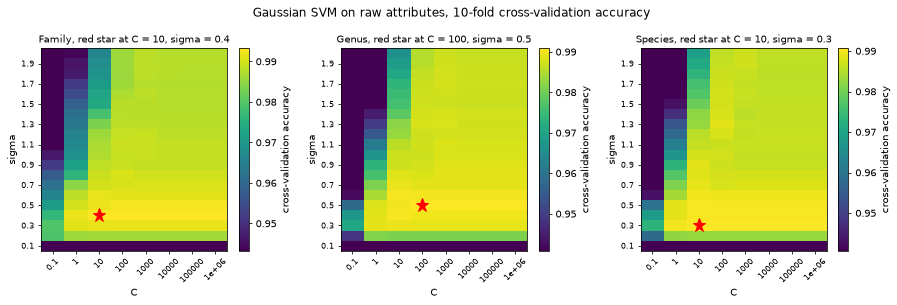

In [7]:
def plot_heat_maps(fits, title):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), dpi=70)
    for ax, col in zip(axes, label_cols):
        f = fits[col]
        table = f["results"].pivot(index="sigma", columns="C", values="accuracy").sort_index()
        im = ax.imshow(table.to_numpy(), origin="lower", aspect="auto", cmap="viridis",
                       vmin=max(table.to_numpy().min(), f["cv accuracy"] - 0.05), vmax=f["cv accuracy"])
        ax.set_xticks(range(table.shape[1]))
        ax.set_xticklabels(["%g" % c for c in table.columns], rotation=45, fontsize=8)
        rows = list(range(0, table.shape[0], 2))
        ax.set_yticks(rows)
        ax.set_yticklabels(["%g" % table.index[i] for i in rows], fontsize=8)
        ax.plot(list(table.columns).index(f["C"]), list(table.index).index(f["sigma"]), marker="*",
                color="red", markersize=14, linestyle="")
        ax.set_xlabel("C")
        ax.set_ylabel("sigma")
        ax.set_title("%s, red star at C = %g, sigma = %g" % (col, f["C"], f["sigma"]), fontsize=10)
        fig.colorbar(im, ax=ax, label="cross-validation accuracy")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_heat_maps(raw_fits, "Gaussian SVM on raw attributes, 10-fold cross-validation accuracy")

On the raw attributes, cross-validation chooses $C = 10$ and $\sigma = 0.4$ for Family, $C = 100$ and $\sigma = 0.5$ for Genus, and $C = 10$ and $\sigma = 0.3$ for Species. Their cross-validation accuracies are 0.9932, 0.9909 and 0.9907. No chosen value is on the edge of its grid, so no grid was extended. The accuracy surface is flat near its top. For Family 66 of the 160 settings are within 0.005 of the best, for Genus 99 and for Species 102. All of these settings have $C$ from 1 to $10^{6}$ and $\sigma$ from 0.3 to 2, which is the wide bright region of the heat maps. The lowest accuracies are 0.7536, 0.7226 and 0.7625, so a poor setting costs much more than the small differences near the top. The cross-validation accuracy of the chosen setting is the best of 160 tries on the same folds, so it is slightly optimistic. The test accuracy in the table further below is the fair estimate.

  Family: chosen sigma = 2 is the upper end of the sigma grid, so sigma = 2.1 is added


  Family: chosen sigma = 2.1 is the upper end of the sigma grid, so sigma = 2.2 is added


  Family: chosen sigma = 2.2 is the upper end of the sigma grid, so sigma = 2.3 is added


  Family: chosen sigma = 2.3 is the upper end of the sigma grid, so sigma = 2.4 is added


  Family: chosen sigma = 2.4 is the upper end of the sigma grid, so sigma = 2.5 is added


  Family: chosen sigma = 2.5 is the upper end of the sigma grid, so sigma = 2.6 is added


... (10 outputs left out)

  Species: chosen sigma = 2.1 is the upper end of the sigma grid, so sigma = 2.2 is added


  Species: chosen sigma = 2.2 is the upper end of the sigma grid, so sigma = 2.3 is added


  Species: chosen sigma = 2.3 is the upper end of the sigma grid, so sigma = 2.4 is added


standardized, Family: chosen C = 10, sigma = 2.8 (gamma = 0.0638), cross-validation accuracy 0.9931
    final grid C 0.1 to 1e+06 and sigma 0.1 to 2.9, 232 settings, accuracy from 0.6142 to 0.9931
    90 settings within 0.005 of the best, with C from 1 to 1e+06 and sigma from 1.7 to 2.9
    chosen value on the edge of the final grid: C False, sigma False
standardized, Genus: chosen C = 10, sigma = 2.5 (gamma = 0.0800), cross-validation accuracy 0.9903
    final grid C 0.1 to 1e+06 and sigma 0.1 to 2.6, 208 settings, accuracy from 0.5766 to 0.9903
    59 settings within 0.005 of the best, with C from 1 to 1e+06 and sigma from 1.8 to 2.6
    chosen value on the edge of the final grid: C False, sigma False
standardized, Species: chosen C = 10, sigma = 2.3 (gamma = 0.0945), cross-validation accuracy 0.9899
    final grid C 0.1 to 1e+06 and sigma 0.1 to 2.4, 192 settings, accuracy from 0.4877 to 0.9899
    41 settings within 0.005 of the best, with C from 1 to 1e+06 and sigma from 1.9 to 2.

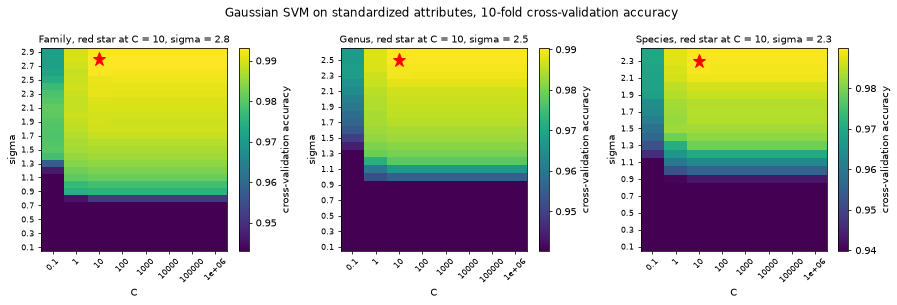

In [8]:
std_fits = {}
for col in label_cols:
    std_fits[col] = search_gaussian(col, standardize=True)
summarize_search("standardized", std_fits)
plot_heat_maps(std_fits, "Gaussian SVM on standardized attributes, 10-fold cross-validation accuracy")

On the standardized attributes the first search chose $\sigma = 2$, the largest grid value, for every label. So the grid of $\sigma$ was extended by 0.1 at a time until the chosen value was inside it. That took nine steps for Family, up to 2.9, six steps for Genus, up to 2.6, and four steps for Species, up to 2.4. The final choices are $C = 10$ for every label, with $\sigma = 2.8$ for Family, $\sigma = 2.5$ for Genus and $\sigma = 2.3$ for Species. None of them is on the edge of its final grid. The cross-validation accuracies are 0.9931, 0.9903 and 0.9899, within 0.0008 of the raw version. The larger $\sigma$ follows from the scale of the attributes. Standardizing divides each MFCC by its standard deviation, which is between 0.0690 and 0.2635 for the raw MFCCs. The distances between rows therefore grow, and the best width of the kernel grows with them.

All choices of part (ii) are now fixed, so the refitted models are scored on the test set. In the tables the two versions are called Gaussian raw and Gaussian standardized. For each version the three label predictions of every test row are joined into a triplet, and the four measures of part (i) are computed. The table also gives the test accuracy and the macro recall of each label. The recall of a class is the share of its test rows that are predicted as that class. The macro recall of a label is the mean of the recalls of its classes. The last line counts the test rows whose predicted triplet is not one of the triplets that occur in the data.

In [9]:
Y_test_array = Y_test[label_cols].to_numpy()
real_triplets = set(map(tuple, Y_all.drop_duplicates().to_numpy()))
test_results = {}
test_predictions = {}
odd_triplets = {}


def test_report(name, fits):
    """Score the refitted models of one classifier on the test set and keep the results."""
    pred = np.column_stack([fits[col]["model"].predict(X_test) for col in label_cols])
    row = {}
    for j, col in enumerate(label_cols):
        row["test accuracy, " + col] = np.mean(pred[:, j] == Y_test_array[:, j])
    row.update(multilabel_scores(Y_test_array, pred))
    for j, col in enumerate(label_cols):
        row["macro recall, " + col] = recall_score(Y_test_array[:, j], pred[:, j], average="macro")
    test_results[name] = row
    test_predictions[name] = pred
    odd_triplets[name] = sum(tuple(t) not in real_triplets for t in pred)


def show_test(names):
    print(pd.DataFrame({name: test_results[name] for name in names}).to_string(float_format="{:.4f}".format))
    print("test rows whose predicted triplet is not in the data:",
          ", ".join("%s %d" % (name, odd_triplets[name]) for name in names))


test_report("Gaussian raw", raw_fits)
test_report("Gaussian standardized", std_fits)
print("number of real triplets in the data:", len(real_triplets))
show_test(["Gaussian raw", "Gaussian standardized"])

number of real triplets in the data: 10
                        Gaussian raw  Gaussian standardized
test accuracy, Family         0.9931                 0.9903
test accuracy, Genus          0.9889                 0.9852
test accuracy, Species        0.9866                 0.9838
exact match ratio             0.9838                 0.9819
Hamming loss                  0.0105                 0.0136
Hamming score                 0.9879                 0.9849
mean Hamming distance         0.0315                 0.0408
macro recall, Family          0.9698                 0.9698
macro recall, Genus           0.9614                 0.9496
macro recall, Species         0.9582                 0.9535
test rows whose predicted triplet is not in the data: Gaussian raw 20, Gaussian standardized 13


Gaussian raw has test accuracies of 0.9931 for Family, 0.9889 for Genus and 0.9866 for Species. Its exact match ratio is 0.9838, so 98.38% of the test rows get all three labels right. Its Hamming loss is 0.0105, its Hamming score 0.9879 and its mean Hamming distance 0.0315. Gaussian standardized is slightly worse on all four measures, with exact match ratio 0.9819, Hamming loss 0.0136, Hamming score 0.9849 and mean Hamming distance 0.0408. Every test accuracy is a little below its cross-validation accuracy, by at most 0.0061, which fits the optimism of the cross-validation value. For Family both versions have a macro recall of 0.9698 to four decimals. For Genus and Species the raw version has the higher macro recall, 0.9614 against 0.9496 and 0.9582 against 0.9535. The three classifiers of a version are trained separately, so some predicted triplets do not occur in the data. This happens for 20 test rows with Gaussian raw and for 13 with Gaussian standardized.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

The L1-penalized SVM uses a linear kernel, as footnote 3 says, through LinearSVC with penalty="l1" [8]. The L1 penalty is the sum of the absolute values of the SVM weights. It can make the weight vectors sparse [8], so it can give some attributes a weight of exactly 0. The model is used with loss="squared_hinge", because LinearSVC does not support the L1 penalty with the plain hinge loss [8]. It also uses dual=False, so the primal problem is solved, as the documentation advises when there are more rows than attributes [8]. For more than two classes LinearSVC trains one-versus-rest classifiers [8], so it is one-versus-all as in part (ii). The attributes are standardized as the handout asks, with a StandardScaler as the first step of a Pipeline.

Only $C$ is chosen, with the same 10 folds, over the 13 values $C = 10^{-3}, 10^{-2.5}, \ldots, 10^{3}$. The grid-edge rule extends this grid by half a decade at a time, and a tie goes to the smaller $C$. LinearSVC runs with max_iter=100000 so that the solver can converge also for the largest values of $C$. It also gets random_state=0, so that repeated runs give exactly the same fit.

In [10]:
l1_exps = [e / 2 for e in range(-6, 7)]        # log10 of C, from -3 to 3 in steps of 0.5


def l1_model(use_smote, C=1.0):
    """StandardScaler, then SMOTE when use_smote is True, then the L1-penalized linear SVM."""
    steps = [("scale", StandardScaler())]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=0)))
    steps.append(("svm", LinearSVC(penalty="l1", loss="squared_hinge", dual=False, C=C, max_iter=100000,
                                   random_state=0)))
    return Pipeline(steps)


def l1_cv(use_smote, y, exps):
    """Mean 10-fold cross-validation accuracy on the training set of every C = 10 ** e for e in exps."""
    search = GridSearchCV(l1_model(use_smote), {"svm__C": [10.0 ** e for e in exps]}, cv=folds,
                          scoring="accuracy", n_jobs=-1, refit=False).fit(X_train, y)
    return pd.DataFrame({"log10 C": exps, "C": [10.0 ** e for e in exps],
                         "accuracy": search.cv_results_["mean_test_score"]})


def search_l1(col, use_smote, max_rounds=30):
    """Choose C for one label, extending the grid by half a decade while the chosen C is on its edge."""
    y = Y_train[col].to_numpy()
    exps = list(l1_exps)
    results = l1_cv(use_smote, y, exps)
    for _ in range(max_rounds):
        best = results.sort_values(["accuracy", "C"], ascending=[False, True]).iloc[0]
        side = edge_side(best["log10 C"], exps)
        if side is None:
            break
        new_e = max(exps) + 0.5 if side == "upper" else min(exps) - 0.5
        print("  %s: chosen C = 10^%g is the %s end of the grid, so C = 10^%g is added"
              % (col, best["log10 C"], side, new_e))
        results = pd.concat([results, l1_cv(use_smote, y, [new_e])], ignore_index=True)
        exps = sorted(exps + [new_e])
    else:
        print("  %s: the chosen C is still on an edge after %d extensions" % (col, max_rounds))
    best = results.sort_values(["accuracy", "C"], ascending=[False, True]).iloc[0]
    model = l1_model(use_smote, best["C"]).fit(X_train, y)
    return {"results": results.sort_values("log10 C"), "C": best["C"], "log10 C": best["log10 C"],
            "cv accuracy": best["accuracy"], "model": model, "grid": exps}


def show_l1(name, fits):
    """Print the cross-validation accuracy of every C and the chosen C of each label."""
    table = pd.DataFrame({col: fits[col]["results"].set_index("log10 C")["accuracy"] for col in label_cols})
    print("%s, mean 10-fold cross-validation accuracy" % name)
    print(table.to_string(float_format="{:.4f}".format))
    print()
    for col in label_cols:
        f = fits[col]
        print("%s: chosen C = 10^%g = %.4g, cross-validation accuracy %.4f, on the edge of the final grid: %s"
              % (col, f["log10 C"], f["C"], f["cv accuracy"], edge_side(f["log10 C"], f["grid"]) is not None))


l1_fits = {}
for col in label_cols:
    l1_fits[col] = search_l1(col, use_smote=False)
show_l1("L1 SVM", l1_fits)

L1 SVM, mean 10-fold cross-validation accuracy
         Family  Genus  Species
log10 C                        
-3.0     0.8548 0.8249   0.7855
-2.5     0.8989 0.8705   0.8654
-2.0     0.9257 0.9142   0.9152
-1.5     0.9349 0.9329   0.9343
-1.0     0.9367 0.9398   0.9480
-0.5     0.9367 0.9474   0.9571
 0.0     0.9367 0.9504   0.9589
 0.5     0.9369 0.9515   0.9595
 1.0     0.9367 0.9517   0.9599
 1.5     0.9369 0.9521   0.9601
 2.0     0.9369 0.9525   0.9601
 2.5     0.9369 0.9525   0.9601
 3.0     0.9369 0.9525   0.9601

Family: chosen C = 10^1.5 = 31.62, cross-validation accuracy 0.9369, on the edge of the final grid: False
Genus: chosen C = 10^2 = 100, cross-validation accuracy 0.9525, on the edge of the final grid: False
Species: chosen C = 10^1.5 = 31.62, cross-validation accuracy 0.9601, on the edge of the final grid: False


With $C$ fixed for every label, the refitted L1-penalized SVMs are scored on the test set in the same way as in part (ii). The weights that the L1 penalty sets to 0 are also counted.

In [11]:
test_report("L1", l1_fits)
show_test(["L1"])
print()
for col in label_cols:
    coef = l1_fits[col]["model"].named_steps["svm"].coef_
    print("%s: %d classes x 22 MFCCs = %d weights, %d of them exactly 0, MFCCs with a nonzero weight for some class %d of 22"
          % (col, coef.shape[0], coef.size, int((coef == 0).sum()), int((coef != 0).any(axis=0).sum())))

                           L1
test accuracy, Family  0.9328
test accuracy, Genus   0.9430
test accuracy, Species 0.9528
exact match ratio      0.9138
Hamming loss           0.0571
Hamming score          0.9343
mean Hamming distance  0.1714
macro recall, Family   0.6873
macro recall, Genus    0.7918
macro recall, Species  0.8860
test rows whose predicted triplet is not in the data: L1 111

Family: 4 classes x 22 MFCCs = 88 weights, 0 of them exactly 0, MFCCs with a nonzero weight for some class 22 of 22
Genus: 8 classes x 22 MFCCs = 176 weights, 0 of them exactly 0, MFCCs with a nonzero weight for some class 22 of 22
Species: 10 classes x 22 MFCCs = 220 weights, 0 of them exactly 0, MFCCs with a nonzero weight for some class 22 of 22


Cross-validation chooses $C = 10^{1.5} = 31.62$ for Family, $C = 10^{2} = 100$ for Genus and $C = 10^{1.5} = 31.62$ for Species. Their cross-validation accuracies are 0.9369, 0.9525 and 0.9601, and no chosen $C$ is on the edge of the grid. For Family the table also shows 0.9369 at $C = 10^{0.5}$, but the unrounded accuracy there is slightly lower, so the tie rule does not apply. The accuracy rises quickly with $C$ and is almost flat at the top. From $C = 1$ up it stays between 0.9367 and 0.9369 for Family, between 0.9504 and 0.9525 for Genus and between 0.9589 and 0.9601 for Species. These accuracies are below those of the Gaussian SVM, 0.9899 to 0.9932, because a linear boundary is less flexible than the Gaussian kernel.

On the test set the L1 SVM, called L1 in the tables, has test accuracies of 0.9328, 0.9430 and 0.9528. Its exact match ratio is 0.9138, its Hamming loss 0.0571, its Hamming score 0.9343 and its mean Hamming distance 0.1714. All four measures are clearly worse than for Gaussian raw, whose exact match ratio is 0.9838. The macro recall is much lower than the test accuracy, for example 0.6873 against 0.9328 for Family. So some of the small classes are mostly missed, and part (iv) shows which ones. At the chosen $C$ none of the weights is exactly 0, so here the L1 penalty does not drop any MFCC. The chosen values of $C$ are large, and a large $C$ means a weak penalty.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

SMOTE (Synthetic Minority Over-sampling Technique) is used to remedy the class imbalance [9]. For a row of a class, SMOTE picks one of its 5 nearest neighbors in the same class [10]. It then creates a new row at a random point on the segment between the two. With its default setting it adds rows to every class except the largest one [9], until each class of the label has as many rows as the largest class. SMOTE must only see the rows that a model is trained on. The Pipeline of imbalanced-learn applies SMOTE only when the pipeline is fitted and never when it predicts [11]. So in each split SMOTE adds rows to the nine training folds only, and the held-out fold and the test set keep only real rows. The pipeline is the StandardScaler, then SMOTE with random_state=0, then the L1-penalized SVM of part (iii), with the same grid, folds and edge rule.

In [12]:
smote_fits = {}
for col in label_cols:
    smote_fits[col] = search_l1(col, use_smote=True)
show_l1("L1 SVM with SMOTE", smote_fits)
print()
for col in label_cols:
    added = sum(smote_fits[col]["model"].named_steps["smote"].sampling_strategy_.values())
    counts = Y_train[col].value_counts()
    print("%s: the final model is fitted on %d training rows plus %d SMOTE rows = %d rows, "
          "which is %d classes x %d rows: %s"
          % (col, len(Y_train), added, len(Y_train) + added, len(counts), counts.max(),
             len(Y_train) + added == len(counts) * counts.max()))

L1 SVM with SMOTE, mean 10-fold cross-validation accuracy
         Family  Genus  Species
log10 C                        
-3.0     0.8217 0.8715   0.9335
-2.5     0.8654 0.8846   0.9478
-2.0     0.8981 0.9035   0.9512
-1.5     0.9104 0.9108   0.9553
-1.0     0.9162 0.9142   0.9561
-0.5     0.9176 0.9156   0.9559
 0.0     0.9180 0.9160   0.9565
 0.5     0.9178 0.9160   0.9565
 1.0     0.9176 0.9162   0.9565
 1.5     0.9176 0.9158   0.9565
 2.0     0.9176 0.9158   0.9565
 2.5     0.9176 0.9158   0.9565
 3.0     0.9176 0.9158   0.9565

Family: chosen C = 10^0 = 1, cross-validation accuracy 0.9180, on the edge of the final grid: False
Genus: chosen C = 10^1 = 10, cross-validation accuracy 0.9162, on the edge of the final grid: False
Species: chosen C = 10^0 = 1, cross-validation accuracy 0.9565, on the edge of the final grid: False

Family: the final model is fitted on 5036 training rows plus 7336 SMOTE rows = 12372 rows, which is 4 classes x 3093 rows: True
Genus: the final model is fitte

                           L1  L1 with SMOTE
test accuracy, Family  0.9328         0.9203
test accuracy, Genus   0.9430         0.9236
test accuracy, Species 0.9528         0.9555
exact match ratio      0.9138         0.8722
Hamming loss           0.0571         0.0669
Hamming score          0.9343         0.9163
mean Hamming distance  0.1714         0.2006
macro recall, Family   0.6873         0.9353
macro recall, Genus    0.7918         0.9233
macro recall, Species  0.8860         0.9284
test rows whose predicted triplet is not in the data: L1 111, L1 with SMOTE 222


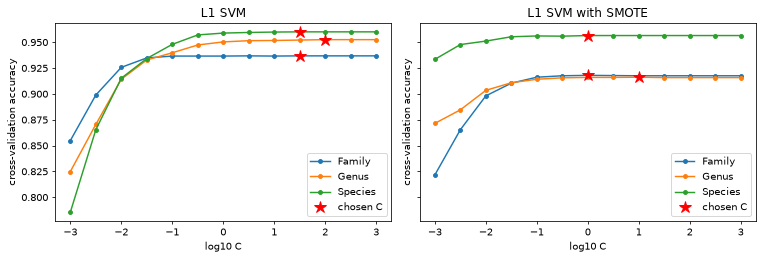

In [13]:
test_report("L1 with SMOTE", smote_fits)
show_test(["L1", "L1 with SMOTE"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), dpi=70, sharey=True)
for ax, (name, fits) in zip(axes, [("L1 SVM", l1_fits), ("L1 SVM with SMOTE", smote_fits)]):
    for col in label_cols:
        r = fits[col]["results"]
        ax.plot(r["log10 C"], r["accuracy"], marker="o", markersize=4, label=col)
    ax.plot([fits[col]["log10 C"] for col in label_cols], [fits[col]["cv accuracy"] for col in label_cols],
            marker="*", color="red", markersize=13, linestyle="", label="chosen C")
    ax.set_xlabel("log10 C")
    ax.set_ylabel("cross-validation accuracy")
    ax.set_title(name)
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

With SMOTE, cross-validation chooses $C = 1$ for Family and Species and $C = 10$ for Genus. Their cross-validation accuracies are 0.9180, 0.9162 and 0.9565, and no chosen $C$ is on the edge of the grid. For Genus the accuracies at $C = 1$ and $C = 10$ are 0.9160 and 0.9162, so that choice is close to a tie. These accuracies are below those of the L1 SVM without SMOTE, 0.9369, 0.9525 and 0.9601. The final models are fitted on 12372, 23232 and 24340 rows, which gives every class 3093, 2904 and 2434 rows. These are the sizes of the largest training class of each label in the split table.

On the test set, L1 with SMOTE has an exact match ratio of 0.8722 and a Hamming loss of 0.0669. Its Hamming score is 0.9163 and its mean Hamming distance is 0.2006. All four measures are worse than without SMOTE, for example 0.8722 against 0.9138 for the exact match ratio. The test accuracy drops for Family, from 0.9328 to 0.9203, and for Genus, from 0.9430 to 0.9236, while it rises a little for Species, from 0.9528 to 0.9555. The macro recall rises for every label, from 0.6873 to 0.9353 for Family, from 0.7918 to 0.9233 for Genus and from 0.8860 to 0.9284 for Species. SMOTE also doubles the number of test rows whose predicted triplet does not occur in the data, from 111 to 222.

The overall accuracy is dominated by the large classes, so the test recall of every class is printed for the four classifiers. The column "test rows" gives the number of test rows of each class.

In [14]:
names = ["Gaussian raw", "Gaussian standardized", "L1", "L1 with SMOTE"]
for j, col in enumerate(label_cols):
    classes = sorted(set(Y_train[col]))
    table = pd.DataFrame({"test rows": [int(np.sum(Y_test_array[:, j] == c)) for c in classes]}, index=classes)
    for name in names:
        table[name] = recall_score(Y_test_array[:, j], test_predictions[name][:, j], labels=classes, average=None)
    print("%s, test recall of every class" % col)
    print(table.to_string(float_format="{:.4f}".format))
    print("macro recall:", ", ".join("%s %.4f" % (name, test_results[name]["macro recall, " + col]) for name in names))
    print()

Family, test recall of every class
                 test rows  Gaussian raw  Gaussian standardized     L1  L1 with SMOTE
Bufonidae               20        0.9000                 0.9000 0.0000         0.9500
Dendrobatidae          163        0.9939                 1.0000 0.8773         0.9816
Hylidae                649        0.9892                 0.9877 0.9045         0.8752
Leptodactylidae       1327        0.9962                 0.9917 0.9676         0.9344
macro recall: Gaussian raw 0.9698, Gaussian standardized 0.9698, L1 0.6873, L1 with SMOTE 0.9353

Genus, test recall of every class
               test rows  Gaussian raw  Gaussian standardized     L1  L1 with SMOTE
Adenomera           1246        0.9968                 0.9920 0.9807         0.9230
Ameerega             163        1.0000                 1.0000 0.9387         0.9632
Dendropsophus         93        0.9570                 0.9570 0.6559         0.8495
Hypsiboas            478        0.9833                 0.9874 0.960

Without SMOTE, the L1 SVM misses many rows of the small classes. Its recall is 0.0000 for Bufonidae, 0.3500 for Rhinella, 0.6176 for Osteocephalus and 0.6559 for Dendropsophus. With SMOTE these recalls rise to 0.9500, 0.9000, 0.9706 and 0.8495. The price is a lower recall for the large classes, for example from 0.9676 to 0.9344 for Leptodactylidae and from 0.9807 to 0.9230 for Adenomera. The Gaussian SVMs reach a recall of 0.9000 for Bufonidae and for Rhinella in both versions without any resampling. The lowest class recall of either Gaussian SVM is 0.8529, for OsteocephalusOophagus in both versions and for Osteocephalus in the standardized version.

The last table collects the test results of the four classifiers that the conclusions below compare.

In [15]:
measures = ["exact match ratio", "Hamming loss", "Hamming score", "mean Hamming distance",
            "macro recall, Family", "macro recall, Genus", "macro recall, Species"]
conclusion = pd.DataFrame(test_results).T.loc[names, measures]
print("test set, all four classifiers")
print(conclusion.to_string(float_format="{:.4f}".format))

test set, all four classifiers
                       exact match ratio  Hamming loss  Hamming score  mean Hamming distance  macro recall, Family  macro recall, Genus  macro recall, Species
Gaussian raw                      0.9838        0.0105         0.9879                 0.0315                0.9698               0.9614                 0.9582
Gaussian standardized             0.9819        0.0136         0.9849                 0.0408                0.9698               0.9496                 0.9535
L1                                0.9138        0.0571         0.9343                 0.1714                0.6873               0.7918                 0.8860
L1 with SMOTE                     0.8722        0.0669         0.9163                 0.2006                0.9353               0.9233                 0.9284


Gaussian raw is the best classifier by all four multi-label measures, with exact match ratio 0.9838, Hamming loss 0.0105, Hamming score 0.9879 and mean Hamming distance 0.0315. By the exact match ratio, Gaussian standardized is close behind with 0.9819, while the two linear classifiers are clearly weaker, with 0.9138 for L1 and 0.8722 for L1 with SMOTE. SMOTE raises the macro recall of the L1 SVM from 0.6873 to 0.9353 for Family, from 0.7918 to 0.9233 for Genus and from 0.8860 to 0.9284 for Species. By macro recall Gaussian raw is the best for Genus and Species, with 0.9614 and 0.9582, and for Family it ties with Gaussian standardized at 0.9698 to four decimals. Both Gaussian SVMs have a higher macro recall than L1 with SMOTE for every label. So by both kinds of measure the Gaussian kernel helps more than SMOTE on this data. With a linear SVM, SMOTE pays off only when the recall of the small classes matters more than the exact match ratio.

#### (v) Extra Practice: Study the Classifier Chain method

The assignment lists 1(b)v as extra practice, and its answer is not submitted.

#### (vi) Extra Practice: Research confusion matrices, precision, recall, ROC, and AUC

The assignment lists 1(b)vi as extra practice, and its answer is not submitted.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

The Monte-Carlo simulation repeats steps (a), (b) and (c) 50 times, with the run number $r = 0, 1, \ldots, 49$ as the random seed of k-means. Every run uses the same data, all 7195 rows and the 22 MFCCs, with no split into training and test sets. The data are not standardized, because the MFCCs are already on one common scale from -1 to 1. So only the random starting centers of k-means change from run to run.

### (a) Use k-means clustering

In each run, k-means is fitted for every number of clusters $k$ from 2 to 50, with n_init=10 random starts and random_state=$r$ [12]. For each $k$ it keeps the start with the smallest within-cluster sum of squares. The number of clusters $k$ is then chosen by the silhouette [13]. For a row, $a$ is its mean distance to the other rows of its cluster and $b$ is its mean distance to the rows of the nearest other cluster. The silhouette of the row is $(b - a)/\max(a, b)$, and the silhouette of a clustering is the mean over all rows. The $k$ with the largest silhouette is chosen. The silhouette is not defined for $k = 1$, because a single cluster has no other cluster, so $k = 1$ is not a candidate. The class labels play no part in this choice, since the function below only receives the 22 MFCCs. The function also keeps the clusters of every $k$, so each $k$ is fitted only once in a run.

run 0: chosen k = 4 with silhouette 0.3788
five largest silhouettes of run 0: k = 4: 0.3788, k = 5: 0.3715, k = 3: 0.3677, k = 2: 0.3487, k = 20: 0.2831
silhouette of run 0 for k = 2 to 10: 2: 0.3487, 3: 0.3677, 4: 0.3788, 5: 0.3715, 6: 0.2644, 7: 0.2604, 8: 0.2545, 9: 0.2761, 10: 0.2811
smallest silhouette of run 0: 0.2127 at k = 47


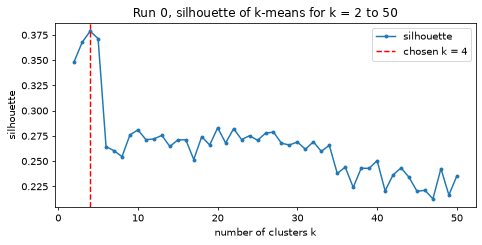

In [16]:
k_values = list(range(2, 51))
n_runs = 50


def choose_k(X, seed):
    """Fit k-means for every k in k_values with random_state=seed. Return the k with the largest
    silhouette, the silhouette of every k and the cluster of every row for every k.
    Only the MFCC matrix X is passed in, so no class label is used."""
    silhouettes, clusters = {}, {}
    for k in k_values:
        fit = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        clusters[k] = fit.labels_
        silhouettes[k] = silhouette_score(X, fit.labels_)
    best_k = max(k_values, key=lambda k: silhouettes[k])
    return best_k, silhouettes, clusters


k0, sil0, clusters0 = choose_k(X_all, 0)
top = sorted(k_values, key=lambda k: -sil0[k])[:5]
print("run 0: chosen k = %d with silhouette %.4f" % (k0, sil0[k0]))
print("five largest silhouettes of run 0:", ", ".join("k = %d: %.4f" % (k, sil0[k]) for k in top))
print("silhouette of run 0 for k = 2 to 10:", ", ".join("%d: %.4f" % (k, sil0[k]) for k in k_values[:9]))
print("smallest silhouette of run 0: %.4f at k = %d" % (min(sil0.values()), min(k_values, key=lambda k: sil0[k])))

fig, ax = plt.subplots(figsize=(7, 3.6), dpi=70)
ax.plot(k_values, [sil0[k] for k in k_values], marker="o", markersize=3, label="silhouette")
ax.axvline(k0, color="red", linestyle="--", label="chosen k = %d" % k0)
ax.set_xlabel("number of clusters k")
ax.set_ylabel("silhouette")
ax.set_title("Run 0, silhouette of k-means for k = 2 to 50")
ax.legend()
plt.tight_layout()
plt.show()

In run 0 the silhouette is largest at $k = 4$, with 0.3788, ahead of $k = 5$ with 0.3715 and $k = 3$ with 0.3677. Every $k$ from 6 to 50 has a silhouette of at most 0.2831, the value at $k = 20$, and the smallest silhouette is 0.2127 at $k = 47$. So run 0 chooses $k = 4$, which happens to equal the number of families.

### (b) Determine which family is the majority

For each cluster of a run, the majority family is the family with the most rows in the cluster, read from the true labels. The majority genus and the majority species are found the same way, each one separately. A tie goes to the class name that comes first in alphabetical order. Because the three majorities are read separately, the triplet of a cluster can pair a genus with a family it does not belong to. The table below checks each triplet of run 0 against the family of every genus and the genus of every species in the data. The cross tables show what the clusters of run 0 contain.

In [17]:
def majority_triplets(clusters, Y):
    """Majority family, genus and species of every cluster, each read separately from the true labels.
    A tie goes to the class name that comes first in alphabetical order."""
    rows = []
    for c in np.unique(clusters):
        members = Y[clusters == c]
        rows.append([c, len(members)] + [members[col].value_counts().sort_index().idxmax() for col in label_cols])
    return pd.DataFrame(rows, columns=["cluster", "rows"] + label_cols).set_index("cluster")


family_of_genus = dict(zip(data["Genus"], data["Family"]))
genus_of_species = dict(zip(data["Species"], data["Genus"]))


def check_triplets(majority):
    """Whether the majority genus of each cluster belongs to its majority family, and the species to the genus."""
    majority = majority.copy()
    majority["genus in family"] = [family_of_genus[g] == f for f, g in zip(majority["Family"], majority["Genus"])]
    majority["species in genus"] = [genus_of_species[s] == g for g, s in zip(majority["Genus"], majority["Species"])]
    return majority


majority0 = check_triplets(majority_triplets(clusters0[k0], Y_all))
print("run 0, k = %d, majority triplet of every cluster" % k0)
print(majority0.to_string())
print()
print("run 0, rows of each family in each cluster")
print(pd.crosstab(Y_all["Family"], clusters0[k0], colnames=["cluster"]).to_string())
print()
print("run 0, rows of each species in each cluster")
print(pd.crosstab(Y_all["Species"], clusters0[k0], colnames=["cluster"]).to_string())

run 0, k = 4, majority triplet of every cluster
         rows           Family      Genus                 Species  genus in family  species in genus
cluster                                                                                             
0        3568  Leptodactylidae  Adenomera  AdenomeraHylaedactylus             True              True
1        1982          Hylidae  Hypsiboas       HypsiboasCordobae             True              True
2        1031    Dendrobatidae   Ameerega      Ameeregatrivittata             True              True
3         614          Hylidae  Hypsiboas    HypsiboasCinerascens             True              True

run 0, rows of each family in each cluster
cluster             0     1    2    3
Family                               
Bufonidae           0    66    0    2
Dendrobatidae       0    42  500    0
Hylidae           101  1245  229  590
Leptodactylidae  3467   629  302   22

run 0, rows of each species in each cluster
cluster                    0 

The four clusters of run 0 have 3568, 1982, 1031 and 614 rows. Their majority triplets are (Leptodactylidae, Adenomera, AdenomeraHylaedactylus), (Hylidae, Hypsiboas, HypsiboasCordobae), (Dendrobatidae, Ameerega, Ameeregatrivittata) and (Hylidae, Hypsiboas, HypsiboasCinerascens). In every cluster the majority genus belongs to the majority family, and the majority species belongs to the majority genus. So no triplet mixes a genus with a family it does not belong to. Two clusters share Hylidae and Hypsiboas and differ only in the species. So in run 0 only 3 of the 4 families, 3 of the 8 genera and 4 of the 10 species are ever assigned. A row of any other class, for example every row of Bufonidae, always gets at least one wrong label.

The clusters do not follow the families, although $k$ equals the number of families. Cluster 0 is almost pure, with 3466 of its 3568 rows from AdenomeraHylaedactylus. Cluster 1 holds rows of all ten species, for example 370 rows of AdenomeraAndre and 253 of LeptodactylusFuscus. Leptodactylidae has 3467 rows in cluster 0 but also 629 in cluster 1 and 302 in cluster 2, and Hylidae has rows in all four clusters.

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

Every row gets the majority triplet of its cluster as its predicted labels, and the four measures of 1(b)i are computed over all 7195 rows with the same function. Run 0 is done above, and runs 1 to 49 follow the same three steps. The handout asks for the mean and the standard deviation of the 50 mean Hamming distances. The same summary is printed for the Hamming loss, the Hamming score and the exact match ratio. The standard deviation uses $50 - 1$ in the denominator.

mixed clusters: clusters whose majority genus is not in its majority family or whose species is not in its genus
 run  k  mean Hamming distance  Hamming loss  Hamming score  exact match ratio  mixed clusters
   0  4                 0.6673        0.2224         0.7703             0.7555               0
   1  4                 0.6673        0.2224         0.7703             0.7555               0
   2  4                 0.7354        0.2451         0.7324             0.6830               0
   3  4                 0.6673        0.2224         0.7703             0.7555               0
   4  4                 0.6673        0.2224         0.7703             0.7555               0
   5  4                 0.6673        0.2224         0.7703             0.7555               0
   6  4                 0.6673        0.2224         0.7703             0.7555               0
   7  4                 0.6673        0.2224         0.7703             0.7555               0
   8  4                 0.6673  

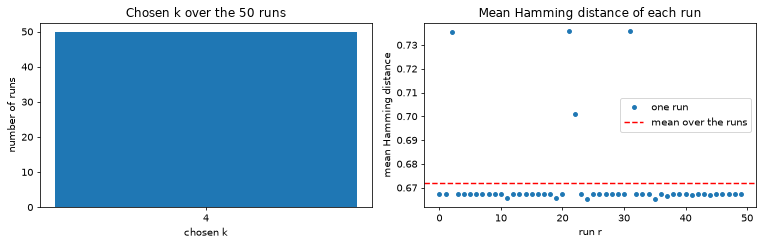

In [18]:
def cluster_scores(clusters, Y):
    """Give every row the majority triplet of its cluster and compute the four measures of 1(b)i.
    Also count the clusters whose genus is not in its family or whose species is not in its genus."""
    majority = check_triplets(majority_triplets(clusters, Y))
    assigned = majority.loc[clusters, label_cols].to_numpy()
    scores = multilabel_scores(Y[label_cols].to_numpy(), assigned)
    scores["mixed clusters"] = int((~(majority["genus in family"] & majority["species in genus"])).sum())
    return scores


runs = [{"run": 0, "k": k0, **cluster_scores(clusters0[k0], Y_all)}]
for r in range(1, n_runs):
    k_r, sil_r, clusters_r = choose_k(X_all, r)
    runs.append({"run": r, "k": k_r, **cluster_scores(clusters_r[k_r], Y_all)})
runs = pd.DataFrame(runs)
run_measures = ["mean Hamming distance", "Hamming loss", "Hamming score", "exact match ratio"]
runs = runs[["run", "k"] + run_measures + ["mixed clusters"]]
print("mixed clusters: clusters whose majority genus is not in its majority family or whose species is not in its genus")
print(runs.to_string(index=False, float_format="{:.4f}".format))
print()
print("mean and standard deviation over the %d runs" % n_runs)
print(runs[run_measures].agg(["mean", "std"]).to_string(float_format="{:.4f}".format))
print()
print("number of runs that chose each k")
print(runs["k"].value_counts().sort_index().to_string())
print()
print("distinct results among the %d runs, with the number of runs that gave each" % n_runs)
print(runs.groupby(["k"] + run_measures).size().reset_index(name="runs").to_string(index=False, float_format="{:.4f}".format))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), dpi=70)
counts = runs["k"].value_counts().sort_index()
axes[0].bar([str(k) for k in counts.index], counts.values)
axes[0].set_xlabel("chosen k")
axes[0].set_ylabel("number of runs")
axes[0].set_title("Chosen k over the %d runs" % n_runs)
axes[1].plot(runs["run"], runs["mean Hamming distance"], marker="o", markersize=4, linestyle="",
             label="one run")
axes[1].axhline(runs["mean Hamming distance"].mean(), color="red", linestyle="--", label="mean over the runs")
axes[1].set_xlabel("run r")
axes[1].set_ylabel("mean Hamming distance")
axes[1].set_title("Mean Hamming distance of each run")
axes[1].legend()
plt.tight_layout()
plt.show()

All 50 runs choose $k = 4$, so the choice of $k$ is completely stable over the random starts. The runs still differ a little, because k-means can end in different clusterings from different starting centers. Nine different results occur, and 35 of the 50 runs give the result of run 0, with mean Hamming distance 0.6673. The three largest mean Hamming distances are 0.7354 in run 2 and 0.7358 in runs 21 and 31.

Over the 50 runs the mean Hamming distance has mean 0.6719 and standard deviation 0.0170, which answers the question of the handout. The Hamming loss has mean 0.2240 and standard deviation 0.0057. The Hamming score has mean 0.7677 and standard deviation 0.0094. The exact match ratio has mean 0.7507 and standard deviation 0.0178. No run produces a cluster whose triplet mixes the levels, since the count of mixed clusters is 0 in every run. A mean Hamming loss of 0.2240 means that on average 22.40% of all labels are wrong. A mean exact match ratio of 0.7507 means that on average about a quarter of the rows get at least one label wrong. The four clusters of run 0 capture the two biggest species, AdenomeraHylaedactylus and HypsiboasCordobae, but they cannot represent all ten species, as part (b) shows.

## 3. ISLR 12.6.2

The four observations have this dissimilarity matrix [14].

$$\begin{bmatrix} & 0.3 & 0.4 & 0.7 \\ 0.3 & & 0.5 & 0.8 \\ 0.4 & 0.5 & & 0.45 \\ 0.7 & 0.8 & 0.45 & \end{bmatrix}$$

Each step of hierarchical clustering fuses the two clusters with the smallest dissimilarity. Complete linkage measures the dissimilarity of two clusters by the largest dissimilarity between their observations, and single linkage by the smallest one [14]. The function linkage of scipy computes both [15], and the dendrograms below mark the height of every fusion. The steps are also printed.

(a) complete linkage
  fuse {1} and {2} at height 0.30
  fuse {3} and {4} at height 0.45
  fuse {1, 2} and {3, 4} at height 0.80
(b) single linkage
  fuse {1} and {2} at height 0.30
  fuse {3} and {1, 2} at height 0.40
  fuse {4} and {1, 2, 3} at height 0.45
(c) two clusters from complete linkage: {1, 2} and {3, 4}
(d) two clusters from single linkage: {1, 2, 3} and {4}
(e) complete linkage with the observations listed as 2, 1, 4, 3
  fuse {2} and {1} at height 0.30
  fuse {4} and {3} at height 0.45
  fuse {1, 2} and {3, 4} at height 0.80
same fusion heights as (a): True


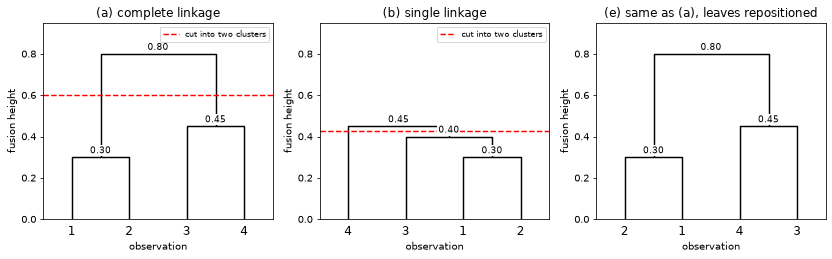

leaf order from left to right: (a) ['1', '2', '3', '4']  (b) ['4', '3', '1', '2']  (e) ['2', '1', '4', '3']


In [19]:
D = np.array([[0.0, 0.3, 0.4, 0.7],
              [0.3, 0.0, 0.5, 0.8],
              [0.4, 0.5, 0.0, 0.45],
              [0.7, 0.8, 0.45, 0.0]])
names = ["1", "2", "3", "4"]
link_complete = linkage(squareform(D), method="complete")
link_single = linkage(squareform(D), method="single")
order = [1, 0, 3, 2]                       # observations 2, 1, 4, 3
link_swapped = linkage(squareform(D[np.ix_(order, order)]), method="complete")
names_swapped = [names[i] for i in order]


def fusion_steps(title, link, labels):
    print(title)
    groups = [[name] for name in labels]
    for a, b, height, size in link:
        left, right = sorted(groups[int(a)], key=int), sorted(groups[int(b)], key=int)
        groups.append(left + right)
        print("  fuse {%s} and {%s} at height %.2f" % (", ".join(left), ", ".join(right), height))


def two_clusters(link, labels):
    member = fcluster(link, 2, criterion="maxclust")
    return " and ".join("{%s}" % ", ".join(sorted(labels[i] for i in range(len(labels)) if member[i] == c))
                        for c in sorted(set(member)))


fusion_steps("(a) complete linkage", link_complete, names)
fusion_steps("(b) single linkage", link_single, names)
print("(c) two clusters from complete linkage:", two_clusters(link_complete, names))
print("(d) two clusters from single linkage:", two_clusters(link_single, names))
fusion_steps("(e) complete linkage with the observations listed as 2, 1, 4, 3", link_swapped, names_swapped)
print("same fusion heights as (a):", np.allclose(link_swapped[:, 2], link_complete[:, 2]))


def draw_dendrogram(ax, link, labels, title, cut):
    d = dendrogram(link, labels=labels, ax=ax, color_threshold=0, above_threshold_color="black")
    for xs, ys in zip(d["icoord"], d["dcoord"]):
        ax.annotate("%.2f" % ys[1], ((xs[1] + xs[2]) / 2, ys[1]), xytext=(0, 4), textcoords="offset points",
                    ha="center", fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=1), zorder=5)
    if cut is not None:
        ax.axhline(cut, color="red", linestyle="--", label="cut into two clusters")
        ax.legend(loc="upper right", fontsize=8)
    ax.set_ylim(0, 0.95)
    ax.set_xlabel("observation")
    ax.set_ylabel("fusion height")
    ax.set_title(title)
    return d["ivl"]


fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), dpi=70)
leaves_a = draw_dendrogram(axes[0], link_complete, names, "(a) complete linkage", 0.6)
leaves_b = draw_dendrogram(axes[1], link_single, names, "(b) single linkage", 0.425)
leaves_e = draw_dendrogram(axes[2], link_swapped, names_swapped, "(e) same as (a), leaves repositioned", None)
plt.tight_layout()
plt.show()
print("leaf order from left to right: (a)", leaves_a, " (b)", leaves_b, " (e)", leaves_e)

(a) Complete linkage. The smallest dissimilarity is 0.3, between observations 1 and 2, so {1, 2} is formed at height 0.3. The complete-linkage dissimilarity from {1, 2} to observation 3 is $\max(0.4, 0.5) = 0.5$, and to observation 4 it is $\max(0.7, 0.8) = 0.8$. The dissimilarity between 3 and 4 is 0.45, the smallest of the three, so {3, 4} is formed at height 0.45. The last step joins {1, 2} and {3, 4} at $\max(0.4, 0.5, 0.7, 0.8) = 0.8$. The printed steps and the first dendrogram give the same heights, 0.30, 0.45 and 0.80.

(b) Single linkage. Again {1, 2} is formed first, at height 0.3. The single-linkage dissimilarity from {1, 2} to observation 3 is $\min(0.4, 0.5) = 0.4$, from {1, 2} to observation 4 it is $\min(0.7, 0.8) = 0.7$, and between 3 and 4 it is 0.45. The smallest is 0.4, so observation 3 joins {1, 2} at height 0.4. Observation 4 then joins at $\min(0.7, 0.8, 0.45) = 0.45$. The printed steps and the second dendrogram give the heights 0.30, 0.40 and 0.45.

(c) Cutting the complete-linkage dendrogram into two clusters, for example at height 0.6, gives the clusters {1, 2} and {3, 4}.

(d) Cutting the single-linkage dendrogram into two clusters, for example at height 0.425, gives the clusters {1, 2, 3} and {4}.

(e) At each fusion the two branches can swap places without changing the meaning of the dendrogram. Swapping 1 with 2 and 3 with 4 in the dendrogram of (a) gives the leaf order 2, 1, 4, 3, shown in the third panel. It has the same fusions at the same heights, 0.30, 0.45 and 0.80, as the printed check confirms.

## 4. Extra Practice: The rest of problems in 12.6

The assignment lists the rest of the problems in ISLR 12.6 as extra practice, and their answers are not submitted.

## References

[1] UCI Machine Learning Repository, Anuran Calls (MFCCs) data set. https://archive.ics.uci.edu/ml/datasets/Anuran+Calls+%28MFCCs%29

[2] M.-L. Zhang and Z.-H. Zhou, A Review on Multi-Label Learning Algorithms, IEEE Transactions on Knowledge and Data Engineering 26(8) (2014) 1819-1837. https://doi.org/10.1109/TKDE.2013.39

[3] scikit-learn, SVC. https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html

[4] scikit-learn user guide, Support Vector Machines. https://scikit-learn.org/stable/modules/svm.html

[5] scikit-learn, OneVsRestClassifier. https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsRestClassifier.html

[6] scikit-learn, StratifiedKFold. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html

[7] scikit-learn, GridSearchCV. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

[8] scikit-learn, LinearSVC. https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html

[9] imbalanced-learn, SMOTE. https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html

[10] imbalanced-learn user guide, Over-sampling. https://imbalanced-learn.org/stable/over_sampling.html

[11] imbalanced-learn, Pipeline. https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html

[12] scikit-learn, KMeans. https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

[13] scikit-learn, silhouette_score. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html

[14] G. James, D. Witten, T. Hastie and R. Tibshirani, An Introduction to Statistical Learning with Applications in R, second edition, Springer, 2021. https://www.statlearning.com/

[15] SciPy, scipy.cluster.hierarchy.linkage. https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html